# 02 — Protocol and metrics

A forecasting comparison is only as good as its protocol. This notebook fixes, once, how every
model in notebooks 03 to 08 is trained, evaluated and compared, and shows why each metric was
chosen. All of it lives in `study.py` so every notebook measures the same thing.

## 1. Rolling origins, never a peek ahead

Each benchmark series has 48 months. We cut it at **7 origins** (cutoffs), every 2 months, the
first one after 24 months of training and the last one 12 months before the end; at each cutoff a
model is trained on the months **up to the cutoff only** and forecasts the next **12 months**.
This is exactly invariant §8.41 of the spec ("each back-test cut trains on the months up to it
only"), and Nixtla's `cross_validation` implements it (`h=12, n_windows=7, step_size=2`). A
random train/test split or k-fold would let the model see the future of a series and is never
used.

The app itself cuts at **every** month from the 13th (the 7th below two years) because it must
choose a model and build bands from one household's history; here, with many series, every
second month is enough and halves the cost. Notebook 06 uses a dense, every-month variant for
the bands.

658 variable series from 60 households, 48 months
cutoffs: ['2023-12', '2024-02', '2024-04', '2024-06', '2024-08', '2024-10', '2024-12']


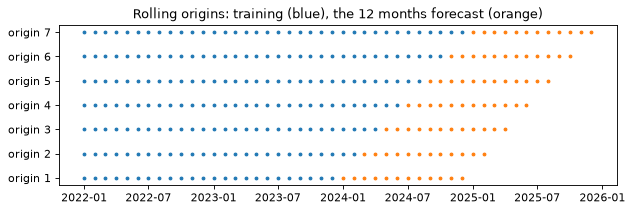

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import HistoricAverage, Naive, SeasonalNaive, WindowAverage

import study

v = study.bench()
cuts = study.cutoffs(v, n_windows=7, step=2)
print(f"{v['unique_id'].nunique()} variable series from 60 households, {v['ds'].nunique()} months")
print("cutoffs:", [c.strftime("%Y-%m") for c in cuts])

fig, ax = plt.subplots(figsize=(9, 2.6))
months = sorted(v["ds"].unique())
for i, c in enumerate(cuts):
    train = [m for m in months if m <= c]
    test = [m for m in months if c < m <= c + pd.DateOffset(months=12)]
    ax.scatter(train, [i] * len(train), s=6, color="tab:blue")
    ax.scatter(test, [i] * len(test), s=6, color="tab:orange")
ax.set(yticks=range(len(cuts)), yticklabels=[f"origin {i + 1}" for i in range(len(cuts))],
       title="Rolling origins: training (blue), the 12 months forecast (orange)")
plt.show()

## 2. Baselines first

A method earns its place only by beating simple ones. Three baselines:

- **naive**: next months = the last month;
- **seasonal naive**: next months = the same months a year earlier;
- **6-month mean**: the app's baseline (F-FCT-3), robust to noise and to the occasional empty
  month.

plus the **historic average** for reference.

In [2]:
sf = StatsForecast(
    models=[Naive(), SeasonalNaive(12), WindowAverage(6, alias="Mean6"), HistoricAverage()],
    freq="MS", n_jobs=-1,
)
cv = sf.cross_validation(df=v[["unique_id", "ds", "y"]], h=12, n_windows=7, step_size=2)
models = ["Naive", "SeasonalNaive", "Mean6", "HistoricAverage"]
cv.head()

,unique_id,ds,cutoff,y,Naive,SeasonalNaive,Mean6,HistoricAverage
0,002/Children,2024-01-01,2023-12-01,237.98,236.48,252.77,322.256667,331.579167
1,002/Children,2024-02-01,2023-12-01,328.57,236.48,329.65,322.256667,331.579167
2,002/Children,2024-03-01,2023-12-01,415.44,236.48,336.21,322.256667,331.579167
3,002/Children,2024-04-01,2023-12-01,226.48,236.48,165.48,322.256667,331.579167
4,002/Children,2024-05-01,2023-12-01,205.50,236.48,240.99,322.256667,331.579167


## 3. Point metrics

For a series $y$, a cutoff with training $y_1..y_T$ and errors $e_h = y_{T+h} - \hat y_{T+h}$:

- **MASE** = mean $|e_h|$ / mean $|y_t - y_{t-1}|$ over the training (Hyndman & Koehler, 2006).
  Scale-free, so a €5 error on health and a €50 error on groceries count alike; defined on empty
  months (unlike MAPE); below 1 means the method errs less, out of sample, than the naive method
  did in sample. The app ranks candidates by it (F-FCT-4).
- **RMSSE** = the squared version (the M5 competition's metric): punishes large misses more, so
  a method that is usually close but sometimes far loses here.
- **WAPE** = $\sum |e| / \sum |y|$ pooled over series: the share of the money forecast wrong, the
  most readable figure for a household ("errs by 12 % of what was spent"), but dominated by the
  large series (salaries, groceries).
- **bias** = $\sum e / \sum |y|$: positive when the forecasts are too low.

A series whose training never changed (scale 0) has an undefined MASE; it is left out of the
averages here, and the app keeps the baseline for it without a contest.

In [3]:
scores = study.point_scores(cv, v, models)
study.summary(scores, baseline="Mean6").round(3)

,MASE,MASE median,RMSSE,WAPE,bias,beats baseline
model,,,,,,
HistoricAverage,0.927,0.811,0.878,0.164,0.023,0.517
SeasonalNaive,0.935,0.875,0.932,0.126,0.012,0.442
Mean6,0.944,0.832,0.893,0.174,0.007,0.000
Naive,1.174,0.895,1.074,0.208,0.002,0.354


Readings. On these 48-month series the baselines are close on the mean MASE (0.93 to 0.94) but
for the **naive** method (1.17): a single month is a noisy guide to the next ones. The
**historic average** and the **6-month mean** rank best (Friedman ranks below); the **seasonal
naive** has the best WAPE, because it wins on the large seasonal series (a 13th month, the
summer holidays) which weigh most in a pooled figure, yet it beats the 6-month mean on only
44 % of the series-origins: it copies last year's noise along with its pattern. No baseline
dominates, which is the case for choosing **per series** (F-FCT-4).

### Why not MAPE

On an intermittent series, an empty month makes the percentage error infinite, and on small
amounts a €10 miss is "100 %". Below, the share of series-months with a zero actual:

In [4]:
print(f"months with nothing entered: {(cv['y'] == 0).mean():.1%} of the forecast months")

months with nothing entered: 22.7% of the forecast months


### Errors grow with the horizon

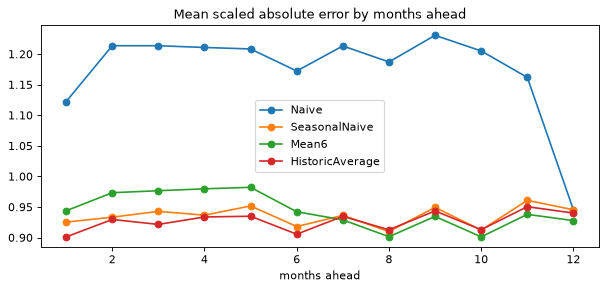

In [5]:
study.by_horizon(cv, v, models).plot(marker="o", title="Mean scaled absolute error by months ahead")
plt.xlabel("months ahead")
plt.show()

### Dispersion, not just a mean

A mean MASE hides how often a method wins. The distribution over series and origins:

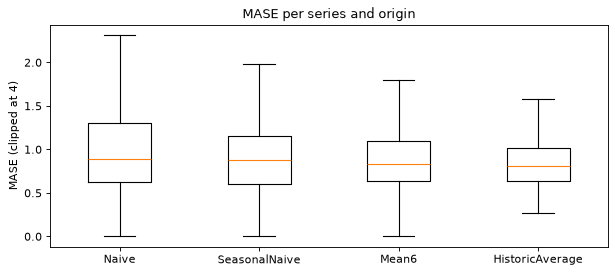

In [6]:
fig, ax = plt.subplots()
data = [scores.loc[scores.model == m, "mase"].dropna().clip(upper=4) for m in models]
ax.boxplot(data, tick_labels=models, showfliers=False)
ax.set(ylabel="MASE (clipped at 4)", title="MASE per series and origin")
plt.show()

## 4. Probabilistic metrics

The app shows an **80 % band** (the 10th to the 90th percentile). A band is judged by:

- **coverage**: the share of actual months inside it, 80 % if calibrated;
- **width** (scaled): narrower is better, *at equal coverage*;
- **MSIS** (mean scaled interval score, M4): width plus a penalty of $2/\alpha$ times the miss
  when the actual falls outside, so it rewards bands that are both narrow and honest;
- **pinball (quantile) loss** at 10 %, 50 %, 90 %, scaled like the MASE;
- **scaled CRPS**, approximated by twice the mean pinball loss over the quantiles available: it
  judges the whole predictive distribution and reduces to the MAE for a point forecast.

Model-based intervals for the baselines that have one, to fix the ideas (statsforecast's
`level=[80]`; a window average has no model-based interval):

In [7]:
sfl = StatsForecast(models=[Naive(), SeasonalNaive(12), HistoricAverage()], freq="MS", n_jobs=-1)
cvl = sfl.cross_validation(df=v[["unique_id", "ds", "y"]], h=12, n_windows=7, step_size=2, level=[80])
rows = []
for m in ["Naive", "SeasonalNaive", "HistoricAverage"]:
    cvl[f"{m}-q50"] = cvl[m]
    rows.append(study.prob_scores(cvl, v, m, {0.1: f"{m}-lo-80", 0.5: f"{m}-q50", 0.9: f"{m}-hi-80"}))
pd.DataFrame(rows).round(3)

,coverage 80%,width / scale,MSIS,pinball 10,pinball 50,pinball 90,scaled CRPS
Naive,0.951,9.965,11.119,0.548,0.587,0.564,1.132
SeasonalNaive,0.810,3.295,5.737,0.267,0.468,0.307,0.694
HistoricAverage,0.847,3.081,5.502,0.208,0.463,0.342,0.676


The naive method's model-based interval is far too wide (95 % coverage, a width of ten times
the scale): its variance grows with the horizon as for a random walk, which monthly spending is
not. The seasonal naive's and the historic average's cover 81 % and 85 % on average, but an
average hides per-category mis-calibration (notebook 06), and most of the candidates the app
may choose (window averages, ADIDA, the trees) have **no** model-based interval at all. That is
why the app builds its bands from the back-test's own errors (conformal), notebook 06.

## 5. Comparing methods fairly

Differences between methods are tested, not eyeballed:

- **Friedman test** and **Nemenyi critical difference** on the average ranks of the MASE over
  series-origins (Demšar, 2006): two methods whose average ranks differ by less than the
  critical difference are not told apart;
- **Diebold–Mariano** (with the Harvey correction) for two methods on one series.

In [8]:
ranks, p, cd = study.friedman_nemenyi(scores)
print(ranks.round(2).to_string())
print(f"Friedman p = {p:.2g}, Nemenyi critical difference = {cd:.3f}")

model
HistoricAverage    2.33
Mean6              2.38
SeasonalNaive      2.55
Naive              2.74
Friedman p = 1.1e-64, Nemenyi critical difference = 0.069


## Summary of the protocol

| Item | Choice |
|---|---|
| Panel | 60 synthetic households, 48 months, their variable series (658) |
| Origins | 7, every 2 months, first after 24 months of training |
| Horizon | 1 to 12 months |
| Point metrics | MASE (ranking), RMSSE, WAPE, bias |
| Probabilistic | coverage and width of the 80 % band, MSIS, pinball 10/50/90, scaled CRPS |
| Tests | Friedman + Nemenyi on ranks, Diebold–Mariano pairwise |
| Baselines | naive, seasonal naive, 6-month mean (the app's), historic average |